In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Визуализация и предобработка

Прогнозируем максимальную температуру следующего дня по предыдущим 30 дням.

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
CSV_PATH = DATA_DIR / "seattle-weather.csv"
SOURCE_URL = "https://www.kaggle.com/datasets/ananthr1/weather-prediction"

NUMERIC_COLUMNS = ["precipitation", "temp_max", "temp_min", "wind"]
TARGET_COLUMN = "temp_max"
LOOKBACK = 30
TRAIN_END = pd.Timestamp("2014-01-01")
VALIDATION_END = pd.Timestamp("2015-01-01")

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 16,
    "font.family": "Times New Roman",
})

Чтение локального CSV

In [ ]:
df = pd.read_csv(CSV_PATH, parse_dates=["date"])
raw_sha256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()

print(f"Размер таблицы: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

Источник: https://www.kaggle.com/datasets/ananthr1/weather-prediction
Размер таблицы: 1461 строк, 6 столбцов


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


Проверка качества данных

In [8]:
df = pd.read_csv(CSV_PATH, parse_dates=["date"])

expected = {'date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather'}

df = df.sort_values('date').set_index('date')
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in NUMERIC_COLUMNS)
calendar = pd.date_range(df.index.min(), df.index.max(), freq='D')
missing_dates = calendar.difference(df.index)

print( 'Пропущенных дат:', len(missing_dates) )
print( 'Дубликатов строк:', df.reset_index().duplicated().sum() )

display(df.isna().sum().rename('Пропуски'))
display(df[NUMERIC_COLUMNS].describe().round(2))

Пропущенных дат: 0
Дубликатов строк: 0


precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
Name: Пропуски, dtype: int64

,precipitation,temp_max,temp_min,wind
count,1461.00,1461.00,1461.00,1461.00
mean,3.03,16.44,8.23,3.24
std,6.68,7.35,5.02,1.44
min,0.00,-1.60,-7.10,0.40
25%,0.00,10.60,4.40,2.20
50%,0.00,15.60,8.30,3.00
75%,2.80,22.20,12.20,4.00
max,55.90,35.60,18.30,9.50


Обучение: **2012–2013**, валидация: **2014**, тест: **2015**.

In [10]:
train_mask = df.index < TRAIN_END
validation_mask = (df.index >= TRAIN_END) & (df.index < VALIDATION_END)
test_mask = df.index >= VALIDATION_END

train = df.loc[train_mask].copy()

split_summary = pd.DataFrame({
    "Период": ["train", "validation", "test"],
    "Количество дней": [train_mask.sum(), validation_mask.sum(), test_mask.sum()],
})

display(split_summary)

,Период,Количество дней
0,train,731
1,validation,365
2,test,365


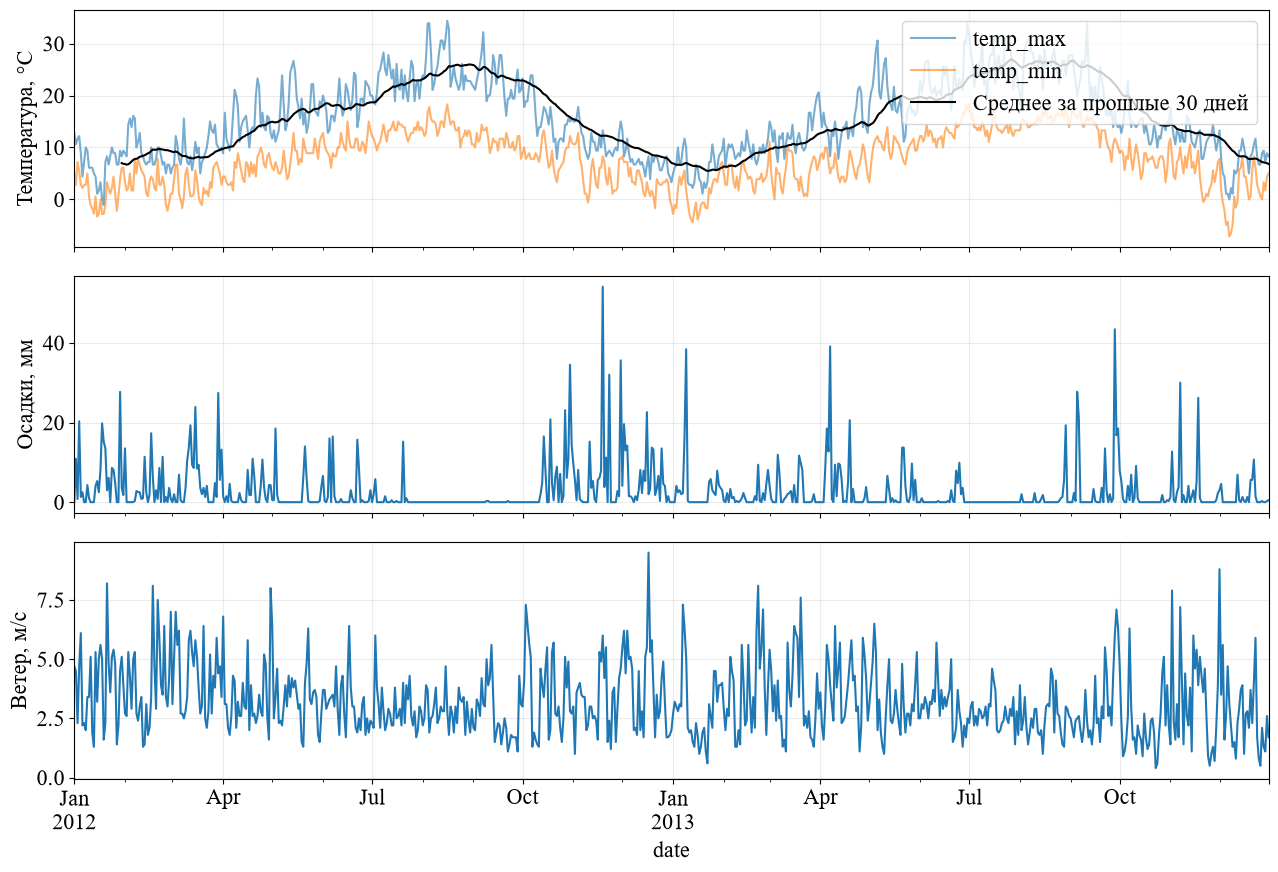

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

train[["temp_max", "temp_min"]].plot(ax=axes[0], alpha=0.6)
temperature_mean_30 = train[TARGET_COLUMN].rolling(window=30).mean()
temperature_mean_30.plot(ax=axes[0], color="black", label="Среднее за прошлые 30 дней")
axes[0].set_ylabel("Температура, °C")
axes[0].legend(loc='upper right')

train["precipitation"].plot(ax=axes[1])
axes[1].set_ylabel("Осадки, мм")

train["wind"].plot(ax=axes[2])
axes[2].set_ylabel("Ветер, м/с")

plt.tight_layout()
plt.show()

Сезонность

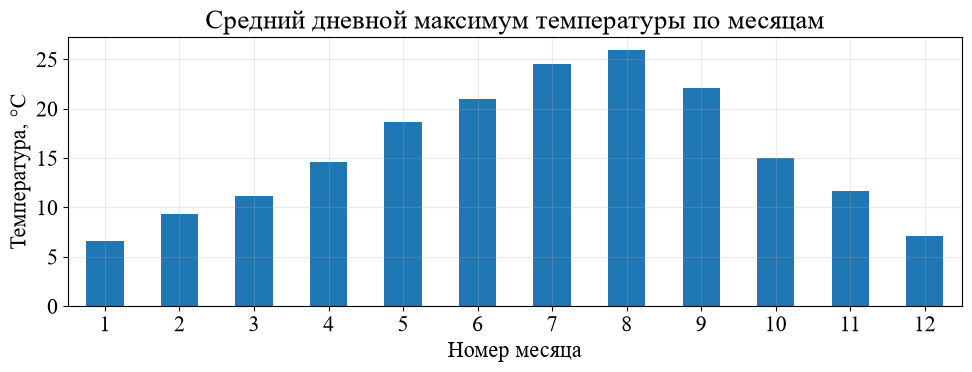

In [24]:
# index.month извлекает номер месяца из каждой даты.
# groupby объединяет дни одного месяца, mean считает среднее.
monthly_temperature = train["temp_max"].groupby(train.index.month).mean()

monthly_temperature.plot.bar(figsize=(10, 4), rot=0)
plt.title("Средний дневной максимум температуры по месяцам")
plt.xlabel("Номер месяца")
plt.ylabel("Температура, °C")
plt.tight_layout()
plt.show()


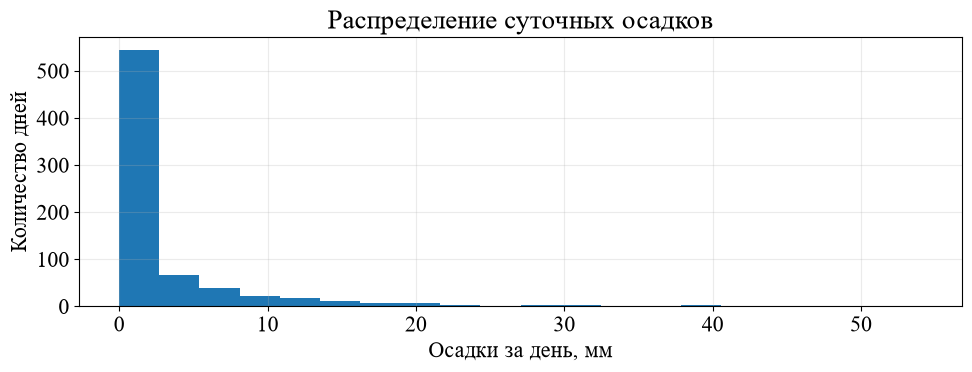

In [ ]:
train["precipitation"].plot.hist(bins=20, figsize=(10, 4))
plt.title("Распределение суточных осадков")
plt.xlabel("Осадки за день, мм")
plt.ylabel("Количество дней")
plt.tight_layout()
plt.show()

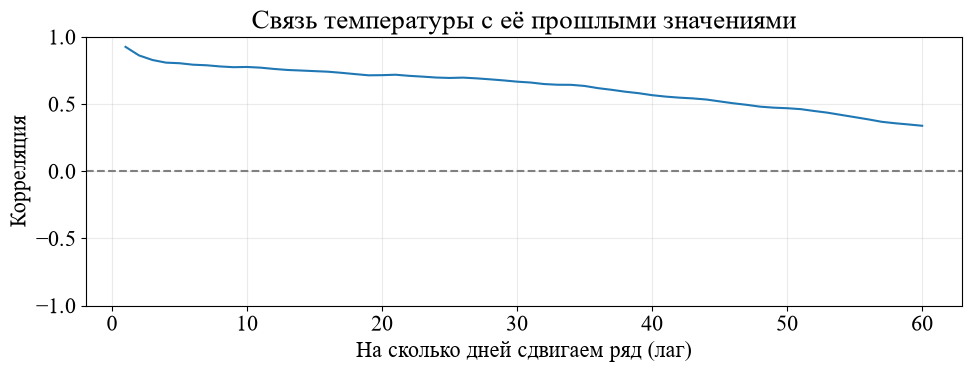

Связь с предыдущим днём: 0.925


In [ ]:
temperature = train["temp_max"]
lags = range(1, 61)
correlations = []

for lag in lags:
    past_temperature = temperature.shift(lag)
    correlation = temperature.corr(past_temperature)
    correlations.append(correlation)

plt.figure(figsize=(10, 4))
plt.plot(lags, correlations)
plt.axhline(0, color="gray", linestyle="--")
plt.ylim(-1, 1)
plt.title("Связь температуры с её прошлыми значениями")
plt.xlabel("На сколько дней сдвигаем ряд (лаг)")
plt.ylabel("Корреляция")
plt.tight_layout()
plt.show()

print(f"Связь с предыдущим днём: {correlations[0]:.3f}")

In [29]:
display(train[NUMERIC_COLUMNS].corr().round(2))
display(pd.crosstab(train.index.year, train["weather"]))

dry_days_fraction = (train["precipitation"] == 0).mean()
lag_one_correlation = train[TARGET_COLUMN].autocorr(lag=1)

print(f"Доля дней без осадков в train: {dry_days_fraction:.1%}")

,precipitation,temp_max,temp_min,wind
precipitation,1.00,-0.23,-0.08,0.30
temp_max,-0.23,1.00,0.87,-0.17
temp_min,-0.08,0.87,1.00,-0.08
wind,0.30,-0.17,-0.08,1.00


weather,drizzle,fog,rain,snow,sun
row_0,,,,,
2012,31,5,191,21,118
2013,15,16,158,3,173


Доля дней без осадков в train: 55.0%


* Осадки асимметричны, с большим числом нулей. Используем `log1p`, затем стандартизацию.
  Большие осадки сами по себе не ошибка: экстремумы не удаляем автоматически.
* Таблица категорий по годам позволяет увидеть нестабильность частот `weather`.
  Причину по этому CSV установить нельзя; категорию в первую модель не включаем.

## 2. Создание признаков

Признаки: Температура, осадки и ветер из таблицы уже являются признаками.

На каждый прошедший день используем:
1. Четыре признака
2. Два числа year_sin и year_cos, обозначающих положение даты в годовом цикле.

log1p преобразует осадки по формуле ln(1 + осадки): ноль остаётся нулём

In [30]:
features = df[NUMERIC_COLUMNS].astype(float).copy()
features["precipitation"] = np.log1p(features["precipitation"])

# Декабрь и январь должны оставаться соседями
days_in_year = np.where(features.index.is_leap_year, 366, 365)
year_phase = 2 * np.pi * (features.index.dayofyear - 1) / days_in_year
features["year_sin"] = np.sin(year_phase)
features["year_cos"] = np.cos(year_phase)

display(features.head())

,precipitation,temp_max,temp_min,wind,year_sin,year_cos
date,,,,,,
2012-01-01,0.000000,12.8,5.0,4.7,0.000000,1.000000
2012-01-02,2.476538,10.6,2.8,4.5,0.017166,0.999853
2012-01-03,0.587787,11.7,7.2,2.3,0.034328,0.999411
2012-01-04,3.058707,12.2,5.6,4.7,0.051479,0.998674
2012-01-05,0.832909,8.9,2.8,6.1,0.068615,0.997643


Масштабирование и стандартизация

Новое значение = (значение − среднее на train) / стандартное отклонение на train.

scaled_x — входные признаки после преобразования, scaled_y — температура-цель.
Цель масштабируется для удобства обучения; прогноз затем возвращаем в °C:
температура = выход модели × y_std + y_mean.

In [ ]:
training_features = features.loc[train_mask]
x_mean = training_features.mean()
x_std = training_features.std(ddof=0).replace(0, 1)

y_mean = float(train[TARGET_COLUMN].mean())
y_std = float(train[TARGET_COLUMN].std(ddof=0))

scaled_x = ((features - x_mean) / x_std).to_numpy(dtype=np.float32)
scaled_y = ((df[TARGET_COLUMN] - y_mean) / y_std).to_numpy(dtype=np.float32)

Временные окна: 30 прошлых дней → следующий день

In [ ]:
input_windows = []
target_values = []

for target_position in range(LOOKBACK, len(df)):
    window_start = target_position - LOOKBACK
    # Правая граница среза не включается: день цели отсутствует во входе.
    input_windows.append(scaled_x[window_start:target_position])
    target_values.append(scaled_y[target_position])

X = np.stack(input_windows)
y = np.asarray(target_values, dtype=np.float32)
target_dates = df.index[LOOKBACK:]

print(f"Вход X: {X.shape} — примеры, дни, признаки")
print(f"Цель y: {y.shape} — одна температура")


Вход X: (1431, 30, 6) — примеры, дни, признаки
Цель y: (1431,) — одна температура на пример


Разделение окон по дате прогнозируемого дня

In [32]:
split_masks = {
    "train": target_dates < TRAIN_END,
    "val": (target_dates >= TRAIN_END) & (target_dates < VALIDATION_END),
    "test": target_dates >= VALIDATION_END,
}

arrays = {}
for split_name, split_mask in split_masks.items():
    split_dates = target_dates[split_mask]
    arrays[f"X_{split_name}"] = X[split_mask]
    arrays[f"y_{split_name}"] = y[split_mask]
    arrays[f"dates_{split_name}"] = split_dates.strftime("%Y-%m-%d").to_numpy(dtype="U10")

    print(
        f"{split_name}: {split_mask.sum()} примеров, "
        f"с {split_dates.min().date()} по {split_dates.max().date()}"
    )

train: 701 примеров, с 2012-01-31 по 2013-12-31
val: 365 примеров, с 2014-01-01 по 2014-12-31
test: 365 примеров, с 2015-01-01 по 2015-12-31


## 3. Сохранение данных для следующих ноутбуков

In [33]:
preprocessing = {
    "target": TARGET_COLUMN,
    "lookback": LOOKBACK,
    "horizon": 1,
    "features": list(features.columns),
    "x_mean": x_mean.to_dict(),
    "x_std": x_std.to_dict(),
    "y_mean": y_mean,
    "y_std": y_std,
    "train_end_exclusive": str(TRAIN_END.date()),
    "val_end_exclusive": str(VALIDATION_END.date()),
    "source": SOURCE_URL,
    "raw_sha256": raw_sha256,
}

np.savez_compressed(ARTIFACTS_DIR / "prepared.npz", **arrays)
df.to_csv(ARTIFACTS_DIR / "observations.csv")

metadata_path = ARTIFACTS_DIR / "preprocessing.json"
metadata_path.write_text(
    json.dumps(preprocessing, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print(f"Результаты сохранены в {ARTIFACTS_DIR}")


Результаты сохранены в C:\Users\sadovets\Dev\BMSTU\IU1_ML\sem2\lab8\artifacts
